<a href="https://colab.research.google.com/github/renzaflorencia/credit-card-unpaid-prediction/blob/main/credit_card_unpaid_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Problem
kekhawatiran adanya keterlambatan pembayaran kartu kredit pada Finaku yang akan merugikan bisnis

#Objective
membuat model yang dapat memprediksi setidaknya 60% dari pelanggan yang akan mengalami telat bayar kartu kredit

#Experiment

Periode tinjauan:
1. nasabah direview selama satu tahun terakhir
2. nasabah direview selama 6 bulan terakhir

penyesuaian variabel:
1. balance dilihat dari rata-rata selama horizon waktu dan dilihat perubahan pada akhir tinjauan dan awal tinjauan
2. melihat kepemilikan jumlah produk dari rata-rata, maksimun dan minimun pada periode tinjauan
3. status keaktifan nasabah dilihat dalam bentuk bulan

In [1]:
!pip install jcopml
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import time
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, classification_report, make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from jcopml.feature_importance import mean_score_decrease

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 57.6 MB/s  0:00:00
  Created wheel for jcopml: filename=jcopml-1.2.7-py2.py3-none-any.whl size=46008 sha256=169bb4becf0ad90ab8328179d0b8b2c09075a80381b373215efa2596a7a7d334
  Stored in directory: /root/.cache/pip/wheels/be/60/e0/87e71013fefa01aa9e72c07d772e1cf0c3fc48493c8c06f89c
Successfully built jcopml
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [jcopml]


In [2]:
pd.set_option('display.max_columns', None)

In [3]:
path_1 = "https://raw.githubusercontent.com/brainspopper/dataset/main/FinanKu%20Data%20All.csv"
path_2 = "https://raw.githubusercontent.com/brainspopper/dataset/main/FinanKu%20Data%20Validasi.csv"

df1 = pd.read_csv(path_1) #df all
df2 = pd.read_csv(path_2)

In [4]:
df1.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0


In [5]:
df2.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0


In [6]:
df1.describe()


,Customer ID,Branch Code,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging
count,7.561000e+03,7561.000000,7561.000000,7.561000e+03,7.561000e+03,7561.000000,7561.000000,7561.000000,7.561000e+03,7561.000000,7561.000000,7561.000000,7.561000e+03,7561.000000,7561.000000,7561.000000,7.561000e+03,7561.000000,7561.0,7561.000000,7561.000000
mean,1.569076e+07,1015.704801,45.713265,2.510237e+07,5.317230e+07,1.524269,0.919191,0.504298,5.324196e+07,1.604682,0.919191,0.522682,5.329437e+07,1.694882,0.919191,0.546224,5.333835e+07,1.783230,1.0,0.580743,0.267028
std,7.224837e+04,7.536500,14.100501,1.190110e+07,5.595802e+07,0.603100,0.272560,0.500015,5.589009e+07,0.662426,0.272560,0.499518,5.584871e+07,0.718528,0.272560,0.497892,5.580800e+07,0.775596,0.0,0.493470,0.442436
min,1.556570e+07,1001.000000,22.000000,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,1.0,0.000000,0.000000
25%,1.562800e+07,1009.000000,34.000000,1.800000e+07,0.000000e+00,1.000000,1.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,6.148609e+05,1.000000,1.000000,0.000000,8.362888e+05,1.000000,1.0,0.000000,0.000000
50%,1.569017e+07,1015.000000,45.000000,2.300000e+07,3.858235e+07,1.000000,1.000000,1.000000,3.866998e+07,2.000000,1.000000,1.000000,3.865399e+07,2.000000,1.000000,1.000000,3.860466e+07,2.000000,1.0,1.000000,0.000000
75%,1.575337e+07,1023.000000,58.000000,3.000000e+07,9.223403e+07,2.000000,1.000000,1.000000,9.223403e+07,2.000000,1.000000,1.000000,9.220094e+07,2.000000,1.000000,1.000000,9.219178e+07,2.000000,1.0,1.000000,1.000000
max,1.581569e+07,1024.000000,70.000000,6.000000e+07,2.942282e+08,4.000000,1.000000,1.000000,2.941728e+08,5.000000,1.000000,1.000000,2.944461e+08,5.000000,1.000000,1.000000,2.946856e+08,5.000000,1.0,1.000000,1.000000


In [7]:
df2.describe()

,Customer ID,Branch Code,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging
count,7.561000e+03,7561.000000,7561.000000,7.561000e+03,7.561000e+03,7561.000000,7561.000000,7561.000000,7.561000e+03,7561.000000,7561.000000,7561.000000,7.561000e+03,7561.000000,7561.0,7561.000000,7.561000e+03,7561.000000,7561.0,7561.000000,7561.000000
mean,1.569076e+07,1015.704801,45.713265,2.510237e+07,5.324196e+07,1.604682,0.919191,0.522682,5.329437e+07,1.694882,0.919191,0.546224,5.333835e+07,1.783230,1.0,0.580743,5.848964e+07,1.923687,1.0,0.458669,0.358286
std,7.224837e+04,7.536500,14.100501,1.190110e+07,5.589009e+07,0.662426,0.272560,0.499518,5.584871e+07,0.718528,0.272560,0.497892,5.580800e+07,0.775596,0.0,0.493470,6.199792e+07,0.903767,0.0,0.498322,0.479528
min,1.556570e+07,1001.000000,22.000000,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,1.000000,1.0,0.000000,0.000000e+00,1.000000,1.0,0.000000,0.000000
25%,1.562800e+07,1009.000000,34.000000,1.800000e+07,0.000000e+00,1.000000,1.000000,0.000000,6.148609e+05,1.000000,1.000000,0.000000,8.362888e+05,1.000000,1.0,0.000000,8.949346e+05,1.000000,1.0,0.000000,0.000000
50%,1.569017e+07,1015.000000,45.000000,2.300000e+07,3.866998e+07,2.000000,1.000000,1.000000,3.865399e+07,2.000000,1.000000,1.000000,3.860466e+07,2.000000,1.0,1.000000,4.213932e+07,2.000000,1.0,0.000000,0.000000
75%,1.575337e+07,1023.000000,58.000000,3.000000e+07,9.223403e+07,2.000000,1.000000,1.000000,9.220094e+07,2.000000,1.000000,1.000000,9.219178e+07,2.000000,1.0,1.000000,1.002271e+08,2.000000,1.0,1.000000,1.000000
max,1.581569e+07,1024.000000,70.000000,6.000000e+07,2.941728e+08,5.000000,1.000000,1.000000,2.944461e+08,5.000000,1.000000,1.000000,2.946856e+08,5.000000,1.0,1.000000,3.683570e+08,7.000000,1.0,1.000000,1.000000


In [8]:
data1 = pd.DataFrame(\
                     #mengemlompokkan berdasarkan kota
                     df1.groupby(by=['City'])["Customer ID"]\
                     .count()\
                     .sort_values(ascending=False)
                     .reset_index(name = "Distributation by City"))
data1

,City,Distributation by City
0,Surabaya,3767
1,Bandung,1898
2,Jakarta,1896


In [9]:
data2 = pd.DataFrame(\
                     #mengemlompokkan berdasarkan kota
                     df1[df1["Unpaid Tagging"]==1].groupby(by=["City"])["Customer ID"]\
                     .count()\
                     .sort_values(ascending=False)
                     .reset_index(name = "Distributation by City"))
data2

,City,Distributation by City
0,Surabaya,1033
1,Bandung,496
2,Jakarta,490


<Axes: title={'center': 'cust distributation by age'}, xlabel='Age', ylabel='People'>

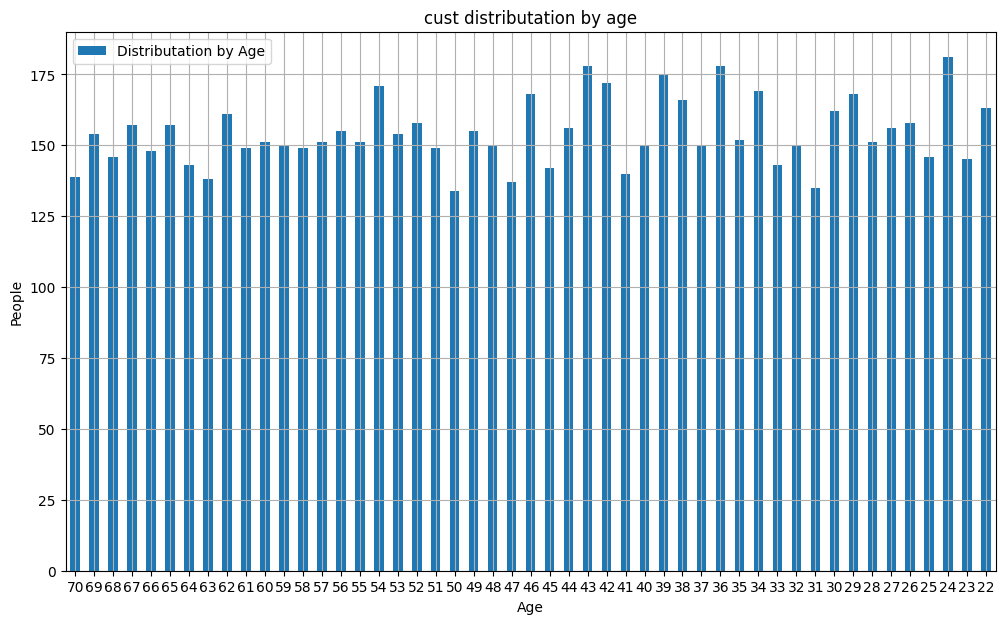

In [10]:
data3 = pd.DataFrame(df1.groupby(by = ['Age'])['Customer ID'].count().reset_index(name = "Distributation by Age"))

data3.sort_values(by=['Age'], ascending = False, inplace = True)

data3.plot(x= 'Age', y=['Distributation by Age'], kind = 'bar',
           grid = True, xlabel = 'Age', ylabel = 'People', figsize = (12,7),
           rot = 0, title = 'cust distributation by age', table = False,
           secondary_y= False
)

<Axes: title={'center': 'unpaid cust, distributation by age'}, xlabel='Age', ylabel='People'>

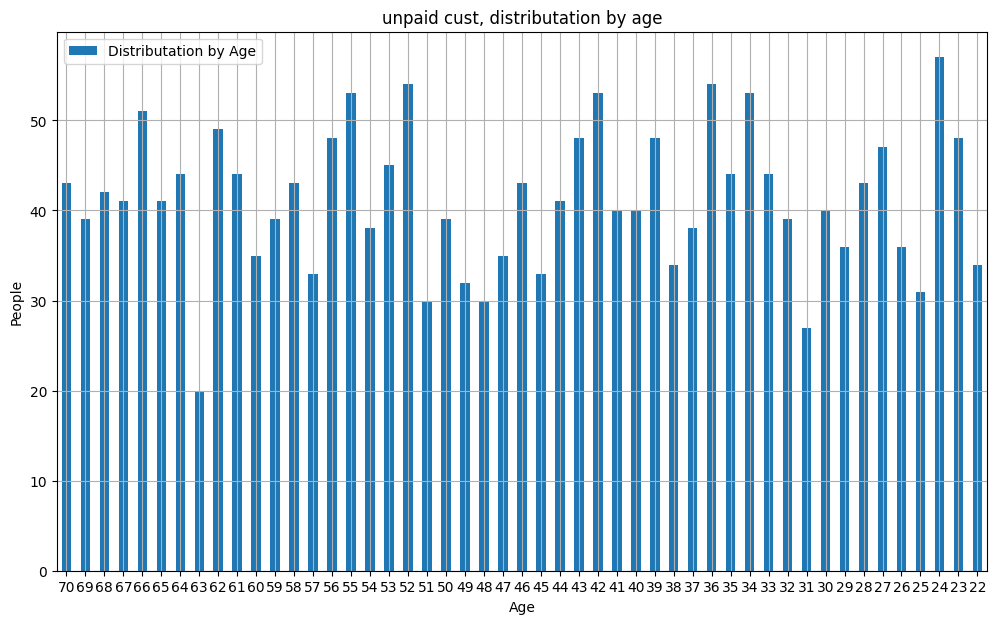

In [11]:
data4 = pd.DataFrame(\
                     #mengemlompokkan berdasarkan kota\
                     df1[df1["Unpaid Tagging"]==1].groupby(by=["Age"])["Customer ID"]\
                     .count()\
                     .reset_index(name = "Distributation by Age"))

data4.sort_values(by=['Age'], ascending = False, inplace = True)

data4.plot(x= 'Age', y=['Distributation by Age'], kind = 'bar',
           grid = True, xlabel = 'Age', ylabel = 'People', figsize = (12,7),
           rot = 0, title = 'unpaid cust, distributation by age', table = False,
           secondary_y= False
)

In [12]:
df_checkbalance = df1

In [13]:
df_checkbalance['Total Balance'] = df_checkbalance['Balance Q1'] + df_checkbalance['Balance Q2'] + df_checkbalance['Balance Q3'] + df_checkbalance['Balance Q4']
df_checkbalance['Avg Balance'] = (df_checkbalance['Balance Q1'] + df_checkbalance['Balance Q2'] + df_checkbalance['Balance Q3'] + df_checkbalance['Balance Q4'])/4

In [14]:
data5 = pd.DataFrame(df_checkbalance.groupby(by = ['Unpaid Tagging'])['Total Balance'].mean().reset_index(name = "Avg Annual Balance"))

data5

,Unpaid Tagging,Avg Annual Balance
0,0,1.985924e+08
1,1,2.527238e+08


In [15]:
data6 = pd.DataFrame(df_checkbalance.groupby(by = ['Unpaid Tagging'])['Avg Balance'].mean().reset_index(name = "Avg Balance"))

data6

,Unpaid Tagging,Avg Balance
0,0,4.964809e+07
1,1,6.318095e+07


In [16]:
df_checkbalance['Avg Product'] = (df_checkbalance['NumOfProducts Q1'] + df_checkbalance['NumOfProducts Q2'] + df_checkbalance['NumOfProducts Q3'] + df_checkbalance['NumOfProducts Q4'])/4

In [17]:
data7 = pd.DataFrame(df_checkbalance.groupby(by = ['Unpaid Tagging'])['Avg Product'].mean().reset_index(name = "Avg Balance"))

data7

,Unpaid Tagging,Avg Balance
0,0,1.667223
1,1,1.609336


In [18]:
df1 = df1.drop(columns= ['Total Balance', 'Avg Balance', 'Avg Product'])

pengecekan data duplikat dan missing data

In [19]:
df1.duplicated().sum()

np.int64(0)

In [20]:
df1.isnull().sum()

,0
Customer ID,0
Branch Code,0
City,0
Age,0
Avg. Annual Income/Month,0
Balance Q1,0
NumOfProducts Q1,0
HasCrCard Q1,0
ActiveMember Q1,0
Balance Q2,0


#Penambahan variabel relevan

1. experiment 1 : rata-rata saldo nasabah dalam 1 tahun terakhir & perubahan saldo di Q4 terhadap Q1
1. experiment 2 : rata-rata saldo nasabah dalam 6 bulan terakhir & perubahan saldo di Q4 terhadap Q2

In [21]:
df1['Mean Balance'] = (df1['Balance Q1'] + df1['Balance Q2'] + df1['Balance Q3'] + df1['Balance Q4'])/4
df1['Delta Balance'] = df1['Balance Q4'] - df1['Balance Q1']

In [22]:
df1.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging,Mean Balance,Delta Balance
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1,296759.045,1187036.18
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0,337955.060,1351820.24
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0,277524.090,431190.68


In [23]:
df2['Mean Balance'] = (df2['Balance Q3'] + df2['Balance Q4'])/2
df2['Delta Balance'] = df2['Balance Q4'] - df2['Balance Q2']

In [24]:
df2.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging,Mean Balance,Delta Balance
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1,593518.09,1187036.18
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1,0.00,0.00
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0,675910.12,1351820.24
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1,0.00,0.00
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0,555048.18,431190.68


#status keaktifan

In [25]:
df1['Active Months'] = (df1['ActiveMember Q1']+ df1['ActiveMember Q2']+ df1['ActiveMember Q3']+ df1['ActiveMember Q4'])/3

In [26]:
df1.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging,Mean Balance,Delta Balance,Active Months
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1,296759.045,1187036.18,0.666667
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0,337955.060,1351820.24,0.333333
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0,277524.090,431190.68,0.666667


In [27]:
df2['Active Months'] = (df2['ActiveMember Q3']+ df2['ActiveMember Q4'])/3

In [28]:
df2.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging,Mean Balance,Delta Balance,Active Months
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1,593518.09,1187036.18,0.333333
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1,0.00,0.00,0.000000
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0,675910.12,1351820.24,0.333333
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1,0.00,0.00,0.000000
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0,555048.18,431190.68,0.666667


Melihat fluktuasi kepemilikan produk nasabah dalam periode observasi

In [29]:
df1['Diff PH'] = df1['NumOfProducts Q4'] - df1['NumOfProducts Q1']

In [30]:
df1.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1,296759.045,1187036.18,0.666667,0
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333,0
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0,337955.060,1351820.24,0.333333,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333,0
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0,277524.090,431190.68,0.666667,0


In [31]:
df2['Diff PH'] = df2['NumOfProducts Q4'] - df2['NumOfProducts Q2']

In [32]:
df2.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1,593518.09,1187036.18,0.333333,0
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1,0.00,0.00,0.000000,0
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0,675910.12,1351820.24,0.333333,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1,0.00,0.00,0.000000,0
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0,555048.18,431190.68,0.666667,0


Lama kepimilikan dalam periode observasi

In [33]:
def assign_cr1(df):
  if df['HasCrCard Q1'] == 1:
    return 12
  elif df['HasCrCard Q2'] == 1:
    return 9
  elif df['HasCrCard Q3'] == 1:
    return 6
  else:
    return 3
  return np.nan

In [34]:
df1['Vintage_CR'] = df1.apply(assign_cr1, axis=1)

In [35]:
df1.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH,Vintage_CR
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1,296759.045,1187036.18,0.666667,0,12
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333,0,12
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0,337955.060,1351820.24,0.333333,0,12
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0,0.000,0.00,0.333333,0,12
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0,277524.090,431190.68,0.666667,0,12


In [36]:
df1.columns

Index(['Customer ID', 'Branch Code', 'City', 'Age', 'Avg. Annual Income/Month',
       'Balance Q1', 'NumOfProducts Q1', 'HasCrCard Q1', 'ActiveMember Q1',
       'Balance Q2', 'NumOfProducts Q2', 'HasCrCard Q2', 'ActiveMember Q2',
       'Balance Q3', 'NumOfProducts Q3', 'HasCrCard Q3', 'ActiveMember Q3',
       'Balance Q4', 'NumOfProducts Q4', 'HasCrCard Q4', 'ActiveMember Q4',
       'Unpaid Tagging', 'Mean Balance', 'Delta Balance', 'Active Months',
       'Diff PH', 'Vintage_CR'],
      dtype='object')

In [37]:
df2.columns

Index(['Customer ID', 'Branch Code', 'City', 'Age', 'Avg. Annual Income/Month',
       'Balance Q2', 'NumOfProducts Q2', 'HasCrCard Q2', 'ActiveMember Q2',
       'Balance Q3', 'NumOfProducts Q3', 'HasCrCard Q3', 'ActiveMember Q3',
       'Balance Q4', 'NumOfProducts Q4', 'HasCrCard Q4', 'ActiveMember Q4',
       'Balance Q5', 'NumOfProducts Q5', 'HasCrCard Q5', 'ActiveMember Q5',
       'Unpaid Tagging', 'Mean Balance', 'Delta Balance', 'Active Months',
       'Diff PH'],
      dtype='object')

In [38]:
def assign_cr2(df):
    if df['HasCrCard Q2'] == 1:
        return 12
    elif df['HasCrCard Q3'] == 1:
        return 9
    elif df['HasCrCard Q4'] == 1:
        return 6
    else:
        return 3
df2['Vintage_CR'] = df2.apply(assign_cr2, axis=1)

In [39]:
df2.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH,Vintage_CR
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1,593518.09,1187036.18,0.333333,0,12
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1,0.00,0.00,0.000000,0,12
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0,675910.12,1351820.24,0.333333,0,12
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1,0.00,0.00,0.000000,0,12
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0,555048.18,431190.68,0.666667,0,12


#Penghapusan Variabel

status kepemilikan sudah digantikan dengan lama kepemilikan

In [40]:
df1 = df1.drop(columns= ['HasCrCard Q1', 'HasCrCard Q2', 'HasCrCard Q3', 'HasCrCard Q4'])
df2 = df2.drop(columns= ['HasCrCard Q2', 'HasCrCard Q3', 'HasCrCard Q4', 'HasCrCard Q5'])

In [41]:
df1 = df1.drop(columns= ['Balance Q1', 'Balance Q2', 'Balance Q3', 'Balance Q4'])
df2 = df2.drop(columns= ['Balance Q2', 'Balance Q3', 'Balance Q4', 'Balance Q5'])

In [42]:
df1 = df1.drop(columns= ['NumOfProducts Q1', 'NumOfProducts Q2', 'NumOfProducts Q3', 'NumOfProducts Q4'])
df2 = df2.drop(columns= ['NumOfProducts Q2', 'NumOfProducts Q3', 'NumOfProducts Q4', 'NumOfProducts Q5'])

In [43]:
df1 = df1.drop(columns= ['ActiveMember Q1', 'ActiveMember Q2', 'ActiveMember Q3', 'ActiveMember Q4'])
df2 = df2.drop(columns= ['ActiveMember Q2', 'ActiveMember Q3', 'ActiveMember Q4', 'ActiveMember Q5'])

#data transformation

In [44]:
predictor1 = df1[df1.columns.difference(['Customer ID','Unpaid Tagging'])]
predictor2 = df2[df2.columns.difference(['Customer ID','Unpaid Tagging'])]

In [45]:
predictor1.head()

,Active Months,Age,Avg. Annual Income/Month,Branch Code,City,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,0.666667,29,33000000,1001,Jakarta,1187036.18,0,296759.045,12
1,0.333333,68,17000000,1005,Jakarta,0.00,0,0.000,12
2,0.333333,25,12000000,1009,Jakarta,1351820.24,0,337955.060,12
3,0.333333,42,19000000,1008,Jakarta,0.00,0,0.000,12
4,0.666667,43,29000000,1009,Jakarta,431190.68,0,277524.090,12


In [46]:
predictor2.head()

,Active Months,Age,Avg. Annual Income/Month,Branch Code,City,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,0.333333,29,33000000,1001,Jakarta,1187036.18,0,593518.09,12
1,0.000000,68,17000000,1005,Jakarta,0.00,0,0.00,12
2,0.333333,25,12000000,1009,Jakarta,1351820.24,0,675910.12,12
3,0.000000,42,19000000,1008,Jakarta,0.00,0,0.00,12
4,0.666667,43,29000000,1009,Jakarta,431190.68,0,555048.18,12


In [47]:
predictor1['Branch Code'] = predictor1['Branch Code'].astype(str)
predictor2['Branch Code'] = predictor2['Branch Code'].astype(str)

/tmp/ipykernel_1733/1205290035.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predictor1['Branch Code'] = predictor1['Branch Code'].astype(str)
/tmp/ipykernel_1733/1205290035.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predictor2['Branch Code'] = predictor2['Branch Code'].astype(str)


In [48]:
predictor1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7561 entries, 0 to 7560
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Active Months             7561 non-null   float64
 1   Age                       7561 non-null   int64  
 2   Avg. Annual Income/Month  7561 non-null   int64  
 3   Branch Code               7561 non-null   object 
 4   City                      7561 non-null   object 
 5   Delta Balance             7561 non-null   float64
 6   Diff PH                   7561 non-null   int64  
 7   Mean Balance              7561 non-null   float64
 8   Vintage_CR                7561 non-null   int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 531.8+ KB


In [49]:
predictor1 = pd.get_dummies(predictor1)
predictor2 = pd.get_dummies(predictor2)

In [50]:
predictor1.head()

,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya
0,0.666667,29,33000000,1187036.18,0,296759.045,12,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,0.333333,68,17000000,0.00,0,0.000,12,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,0.333333,25,12000000,1351820.24,0,337955.060,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False
3,0.333333,42,19000000,0.00,0,0.000,12,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
4,0.666667,43,29000000,431190.68,0,277524.090,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False


In [51]:
predictor2.head()

,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya
0,0.333333,29,33000000,1187036.18,0,593518.09,12,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,0.000000,68,17000000,0.00,0,0.00,12,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,0.333333,25,12000000,1351820.24,0,675910.12,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False
3,0.000000,42,19000000,0.00,0,0.00,12,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
4,0.666667,43,29000000,431190.68,0,555048.18,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False


In [52]:
predname = predictor1.columns
predname_num = predictor1.columns[0:7]
predname_cat = predictor1.columns[7:31]

In [53]:
predname

Index(['Active Months', 'Age', 'Avg. Annual Income/Month', 'Delta Balance',
       'Diff PH', 'Mean Balance', 'Vintage_CR', 'Branch Code_1001',
       'Branch Code_1002', 'Branch Code_1003', 'Branch Code_1004',
       'Branch Code_1005', 'Branch Code_1006', 'Branch Code_1007',
       'Branch Code_1008', 'Branch Code_1009', 'Branch Code_1011',
       'Branch Code_1012', 'Branch Code_1013', 'Branch Code_1014',
       'Branch Code_1015', 'Branch Code_1021', 'Branch Code_1022',
       'Branch Code_1023', 'Branch Code_1024', 'City_Bandung', 'City_Jakarta',
       'City_Surabaya'],
      dtype='object')

In [54]:
predname_num

Index(['Active Months', 'Age', 'Avg. Annual Income/Month', 'Delta Balance',
       'Diff PH', 'Mean Balance', 'Vintage_CR'],
      dtype='object')

In [55]:
predname_cat

Index(['Branch Code_1001', 'Branch Code_1002', 'Branch Code_1003',
       'Branch Code_1004', 'Branch Code_1005', 'Branch Code_1006',
       'Branch Code_1007', 'Branch Code_1008', 'Branch Code_1009',
       'Branch Code_1011', 'Branch Code_1012', 'Branch Code_1013',
       'Branch Code_1014', 'Branch Code_1015', 'Branch Code_1021',
       'Branch Code_1022', 'Branch Code_1023', 'Branch Code_1024',
       'City_Bandung', 'City_Jakarta', 'City_Surabaya'],
      dtype='object')

In [56]:
x1_num= predictor1[predname_num]
x2_num= predictor2[predname_num]
x1_cat= predictor1[predname_cat]
x2_cat= predictor2[predname_cat]

In [57]:
from sklearn.preprocessing import StandardScaler
pt = StandardScaler()
x1_num = pd.DataFrame(pt.fit_transform(x1_num))
x1_num.head()


,0,1,2,3,4,5,6
0,-0.135176,-1.185374,0.663649,1.964593,-0.531491,-0.947970,0.296502
1,-1.013239,1.580668,-0.680854,-0.319523,-0.531491,-0.953281,0.296502
2,-1.013239,-1.469071,-1.101011,2.281673,-0.531491,-0.947232,0.296502
3,-1.013239,-0.263360,-0.512791,-0.319523,-0.531491,-0.953281,0.296502
4,-0.135176,-0.192436,0.327524,0.510182,-0.531491,-0.948314,0.296502


In [58]:
x1_num.columns = predname_num
x1_num.head()

,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,-0.135176,-1.185374,0.663649,1.964593,-0.531491,-0.947970,0.296502
1,-1.013239,1.580668,-0.680854,-0.319523,-0.531491,-0.953281,0.296502
2,-1.013239,-1.469071,-1.101011,2.281673,-0.531491,-0.947232,0.296502
3,-1.013239,-0.263360,-0.512791,-0.319523,-0.531491,-0.953281,0.296502
4,-0.135176,-0.192436,0.327524,0.510182,-0.531491,-0.948314,0.296502


In [59]:
x2_num = pd.DataFrame(pt.fit_transform(x2_num))
x2_num.head()

,0,1,2,3,4,5,6
0,-0.165835,-1.185374,0.663649,2.641819,-0.440014,-0.944440,0.296502
1,-1.471959,1.580668,-0.680854,-0.233476,-0.440014,-0.955071,0.296502
2,-0.165835,-1.469071,-1.101011,3.040967,-0.440014,-0.942964,0.296502
3,-1.471959,-0.263360,-0.512791,-0.233476,-0.440014,-0.955071,0.296502
4,1.140289,-0.192436,0.327524,0.810974,-0.440014,-0.945129,0.296502


In [60]:
x2_num.columns = predname_num
x2_num.head()

,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,-0.165835,-1.185374,0.663649,2.641819,-0.440014,-0.944440,0.296502
1,-1.471959,1.580668,-0.680854,-0.233476,-0.440014,-0.955071,0.296502
2,-0.165835,-1.469071,-1.101011,3.040967,-0.440014,-0.942964,0.296502
3,-1.471959,-0.263360,-0.512791,-0.233476,-0.440014,-0.955071,0.296502
4,1.140289,-0.192436,0.327524,0.810974,-0.440014,-0.945129,0.296502


#Menggabungkan dataset

In [61]:
x1 = pd.concat([x1_cat, x1_num], axis = 1)
x2 = pd.concat([x2_cat, x2_num], axis = 1)

In [62]:
x1.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-1.185374,0.663649,1.964593,-0.531491,-0.947970,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,1.580668,-0.680854,-0.319523,-0.531491,-0.953281,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-1.469071,-1.101011,2.281673,-0.531491,-0.947232,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-0.263360,-0.512791,-0.319523,-0.531491,-0.953281,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-0.192436,0.327524,0.510182,-0.531491,-0.948314,0.296502


In [63]:
x2.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-0.165835,-1.185374,0.663649,2.641819,-0.440014,-0.944440,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.471959,1.580668,-0.680854,-0.233476,-0.440014,-0.955071,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.165835,-1.469071,-1.101011,3.040967,-0.440014,-0.942964,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.471959,-0.263360,-0.512791,-0.233476,-0.440014,-0.955071,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,1.140289,-0.192436,0.327524,0.810974,-0.440014,-0.945129,0.296502


#Validation

In [64]:
df1_val = pd.read_csv(path_1)
df2_val = pd.read_csv(path_2)

In [65]:
df1_val.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q1,NumOfProducts Q1,HasCrCard Q1,ActiveMember Q1,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Unpaid Tagging
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,1,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,1,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,0


In [66]:
df2_val.head()

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,Balance Q2,NumOfProducts Q2,HasCrCard Q2,ActiveMember Q2,Balance Q3,NumOfProducts Q3,HasCrCard Q3,ActiveMember Q3,Balance Q4,NumOfProducts Q4,HasCrCard Q4,ActiveMember Q4,Balance Q5,NumOfProducts Q5,HasCrCard Q5,ActiveMember Q5,Unpaid Tagging
0,15565701,1001,Jakarta,29,33000000,0.0,1,1,0,0.00,1,1,0,1187036.18,1,1,1,1305739.798,1,1,1,1
1,15565878,1005,Jakarta,68,17000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,2,1,0,1
2,15566091,1009,Jakarta,25,12000000,0.0,2,1,0,0.00,2,1,0,1351820.24,2,1,1,1622184.288,2,1,1,0
3,15566292,1008,Jakarta,42,19000000,0.0,2,1,0,0.00,2,1,0,0.00,2,1,0,0.000,4,1,0,1
4,15566312,1009,Jakarta,43,29000000,0.0,2,1,0,678905.68,2,1,1,431190.68,2,1,1,431190.680,3,1,0,0


In [67]:
df1_val['Mean Balance'] = (df1_val['Balance Q1'] + df1_val['Balance Q2'] + df1_val['Balance Q3'] + df1_val['Balance Q4']) / 4
df2_val['Mean Balance'] = (df2_val['Balance Q4'] + df2_val['Balance Q5']) / 2

In [68]:
df1_val['Delta Balance'] = df1_val['Balance Q4'] - df1_val['Balance Q1']
df2_val['Delta Balance'] = df2_val['Balance Q5'] - df2_val['Balance Q3']

#status keaktifan

In [69]:
df1_val['Active Months'] = (df1_val['ActiveMember Q1']+ df1_val['ActiveMember Q2']+ df1_val['ActiveMember Q3']+ df1_val['ActiveMember Q4'])*3
df2_val['Active Months'] = (df2_val['ActiveMember Q4']+ df2_val['ActiveMember Q5'])*3

#penambahan / pengurangan product holding

In [70]:
df1_val['Diff PH'] = df1_val['NumOfProducts Q4'] - df1_val['NumOfProducts Q1']
df2_val['Diff PH'] = df2_val['NumOfProducts Q5'] - df1_val['NumOfProducts Q3']

In [71]:
df1_val['Vintage_CR'] = df1_val.apply(assign_cr2, axis=1)
df2_val['Vintage_CR'] = df2_val.apply(assign_cr2, axis=1)

#Penghapusan variabel

In [72]:
df1_val = df1_val.drop(columns = ['HasCrCard Q1', 'HasCrCard Q2', 'HasCrCard Q3', 'HasCrCard Q4', 'Balance Q1', 'Balance Q2', 'Balance Q3', 'Balance Q4', 'NumOfProducts Q1', 'NumOfProducts Q2', 'NumOfProducts Q3', 'NumOfProducts Q4'])
df2_val = df2_val.drop(columns = ['HasCrCard Q2', 'HasCrCard Q3', 'HasCrCard Q4', 'HasCrCard Q5', 'Balance Q2', 'Balance Q3', 'Balance Q4', 'Balance Q5', 'NumOfProducts Q2', 'NumOfProducts Q3', 'NumOfProducts Q4', 'NumOfProducts Q5'])

In [73]:
df1_val.head(10)

,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,ActiveMember Q1,ActiveMember Q2,ActiveMember Q3,ActiveMember Q4,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH,Vintage_CR
0,15565701,1001,Jakarta,29,33000000,1,0,0,1,1,2.967590e+05,1187036.18,6,0,12
1,15565878,1005,Jakarta,68,17000000,1,0,0,0,0,0.000000e+00,0.00,3,0,12
2,15566091,1009,Jakarta,25,12000000,0,0,0,1,0,3.379551e+05,1351820.24,3,0,12
3,15566292,1008,Jakarta,42,19000000,1,0,0,0,0,0.000000e+00,0.00,3,0,12
4,15566312,1009,Jakarta,43,29000000,0,0,1,1,0,2.775241e+05,431190.68,6,0,12
5,15566495,1005,Jakarta,27,15000000,1,0,1,1,0,5.306120e+07,346243.00,9,0,12
6,15566543,1003,Jakarta,68,26000000,1,1,1,0,0,1.099276e+08,-792643.00,9,1,12
7,15566594,1008,Jakarta,61,24000000,0,0,0,0,1,0.000000e+00,0.00,0,0,12
8,15566689,1003,Jakarta,43,38000000,1,0,1,0,0,1.498031e+05,299606.24,6,1,12
9,15566958,1005,Jakarta,70,23000000,0,1,1,0,1,7.960149e+07,-581026.00,6,0,6


In [74]:
df2_val.head(10)


,Customer ID,Branch Code,City,Age,Avg. Annual Income/Month,ActiveMember Q2,ActiveMember Q3,ActiveMember Q4,ActiveMember Q5,Unpaid Tagging,Mean Balance,Delta Balance,Active Months,Diff PH,Vintage_CR
0,15565701,1001,Jakarta,29,33000000,0,0,1,1,1,1.246388e+06,1.305740e+06,6,0,12
1,15565878,1005,Jakarta,68,17000000,0,0,0,0,1,0.000000e+00,0.000000e+00,0,0,12
2,15566091,1009,Jakarta,25,12000000,0,0,1,1,0,1.487002e+06,1.622184e+06,6,0,12
3,15566292,1008,Jakarta,42,19000000,0,0,0,0,1,0.000000e+00,0.000000e+00,0,2,12
4,15566312,1009,Jakarta,43,29000000,0,1,1,0,0,4.311907e+05,-2.477150e+05,3,1,12
5,15566495,1005,Jakarta,27,15000000,0,1,1,1,0,5.990946e+07,1.338732e+07,6,0,12
6,15566543,1003,Jakarta,68,26000000,1,1,0,1,0,1.370369e+08,5.481477e+07,3,1,12
7,15566594,1008,Jakarta,61,24000000,0,0,0,0,1,0.000000e+00,0.000000e+00,0,0,12
8,15566689,1003,Jakarta,43,38000000,0,1,0,0,0,2.996062e+05,0.000000e+00,0,1,12
9,15566958,1005,Jakarta,70,23000000,1,1,0,1,0,8.535666e+07,1.191023e+07,3,0,6


#pemilihan variabel

In [75]:
predictor1_val = df1_val[df1_val.columns.difference(['Customer ID','Unpaid Tagging'])]
predictor2_val = df2_val[df2_val.columns.difference(['Customer ID','Unpaid Tagging'])]

In [76]:
predictor1_val['Branch Code'] = predictor1_val['Branch Code'].astype(str)
predictor2_val['Branch Code'] = predictor2_val['Branch Code'].astype(str)

/tmp/ipykernel_1733/2594155773.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predictor1_val['Branch Code'] = predictor1_val['Branch Code'].astype(str)
/tmp/ipykernel_1733/2594155773.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  predictor2_val['Branch Code'] = predictor2_val['Branch Code'].astype(str)


In [77]:
predictor1_val = pd.get_dummies(predictor1_val)
predictor2_val = pd.get_dummies(predictor2_val)

In [78]:
predictor1_val.head()

,Active Months,ActiveMember Q1,ActiveMember Q2,ActiveMember Q3,ActiveMember Q4,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya
0,6,1,0,0,1,29,33000000,1187036.18,0,296759.045,12,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,3,1,0,0,0,68,17000000,0.00,0,0.000,12,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,3,0,0,0,1,25,12000000,1351820.24,0,337955.060,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False
3,3,1,0,0,0,42,19000000,0.00,0,0.000,12,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
4,6,0,0,1,1,43,29000000,431190.68,0,277524.090,12,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False


In [79]:
x1_num_val = predictor1_val[predname_num]
x2_num_val = predictor2_val[predname_num]
x1_cat_val = predictor1_val[predname_cat]
x2_cat_val = predictor2_val[predname_cat]

In [80]:
x1_num_val = pd.DataFrame(pt.fit_transform(x1_num_val))
x1_num_val.columns = predname_num
x2_num_val = pd.DataFrame(pt.fit_transform(x2_num_val))
x2_num_val.columns = predname_num

In [81]:
x1_val = pd.concat([x1_cat_val, x1_num_val], axis = 1)
x2_val = pd.concat([x2_cat_val, x2_num_val], axis = 1)

In [82]:
x1_val.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-1.185374,0.663649,1.964593,-0.531491,-0.947970,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,1.580668,-0.680854,-0.319523,-0.531491,-0.953281,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-1.469071,-1.101011,2.281673,-0.531491,-0.947232,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-0.263360,-0.512791,-0.319523,-0.531491,-0.953281,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-0.192436,0.327524,0.510182,-0.531491,-0.948314,0.296502


In [83]:
x2_val.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,1.254342,-1.185374,0.663649,-0.367984,-0.419420,-0.930631,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.357273,1.580668,-0.680854,-0.491518,-0.419420,-0.951848,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,1.254342,-1.469071,-1.101011,-0.338045,-0.419420,-0.926535,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.357273,-0.263360,-0.512791,-0.491518,3.246748,-0.951848,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.051466,-0.192436,0.327524,-0.514954,1.413664,-0.944508,0.296502


In [84]:
y1_val = df1_val['Unpaid Tagging']
y2_val = df2_val['Unpaid Tagging']

#pengecekan korelasi

In [85]:
corrtest1 = x1.corr().abs()
corrtest2 = x2.corr().abs()

In [86]:
corrtest1

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
Branch Code_1001,1.000000,0.028917,0.028917,0.029673,0.029331,0.027640,0.028000,0.028214,0.028707,0.040203,0.039566,0.039353,0.038159,0.037440,0.064383,0.062555,0.063414,0.065268,0.098089,0.292872,0.168829,0.000365,0.010394,0.003603,0.001462,0.003888,0.009732,0.020774
Branch Code_1002,0.028917,1.000000,0.029128,0.029889,0.029545,0.027842,0.028204,0.028420,0.028917,0.040496,0.039855,0.039639,0.038437,0.037713,0.064852,0.063011,0.063876,0.065744,0.098804,0.295007,0.170060,0.007664,0.006371,0.016078,0.004592,0.003957,0.005634,0.034256
Branch Code_1003,0.028917,0.029128,1.000000,0.029889,0.029545,0.027842,0.028204,0.028420,0.028917,0.040496,0.039855,0.039639,0.038437,0.037713,0.064852,0.063011,0.063876,0.065744,0.098804,0.295007,0.170060,0.018168,0.013724,0.001937,0.008577,0.004227,0.001776,0.021341
Branch Code_1004,0.029673,0.029889,0.029889,1.000000,0.030318,0.028570,0.028941,0.029163,0.029673,0.041555,0.040897,0.040676,0.039442,0.038699,0.066548,0.064658,0.065546,0.067463,0.101388,0.302721,0.174506,0.001120,0.008420,0.002095,0.015427,0.001172,0.013269,0.003376
Branch Code_1005,0.029331,0.029545,0.029545,0.030318,1.000000,0.028241,0.028608,0.028827,0.029331,0.041076,0.040426,0.040208,0.038988,0.038253,0.065782,0.063914,0.064792,0.066686,0.100221,0.299236,0.172498,0.011655,0.001335,0.008829,0.010599,0.001569,0.007520,0.002246
Branch Code_1006,0.027640,0.027842,0.027842,0.028570,0.028241,1.000000,0.026959,0.027165,0.027640,0.038708,0.038095,0.037889,0.036740,0.036048,0.061989,0.060229,0.061056,0.062841,0.094442,0.281983,0.162551,0.006704,0.004534,0.007488,0.000112,0.017499,0.004003,0.008669
Branch Code_1007,0.028000,0.028204,0.028204,0.028941,0.028608,0.026959,1.000000,0.027518,0.028000,0.039212,0.038591,0.038383,0.037219,0.036517,0.062796,0.061013,0.061851,0.063659,0.095672,0.285654,0.164668,0.010148,0.011408,0.024003,0.002511,0.018648,0.006408,0.003749
Branch Code_1008,0.028214,0.028420,0.028420,0.029163,0.028827,0.027165,0.027518,1.000000,0.028214,0.039511,0.038886,0.038676,0.037503,0.036796,0.063276,0.061479,0.062323,0.064146,0.096403,0.287836,0.165926,0.000426,0.005992,0.000678,0.003350,0.006413,0.001808,0.016428
Branch Code_1009,0.028707,0.028917,0.028917,0.029673,0.029331,0.027640,0.028000,0.028214,1.000000,0.040203,0.039566,0.039353,0.038159,0.037440,0.064383,0.062555,0.063414,0.065268,0.098089,0.292872,0.168829,0.002480,0.002933,0.012510,0.001391,0.012129,0.005874,0.014582
Branch Code_1011,0.040203,0.040496,0.040496,0.041555,0.041076,0.038708,0.039212,0.039511,0.040203,1.000000,0.055410,0.055110,0.053439,0.052431,0.090163,0.087603,0.088806,0.091403,0.409857,0.137270,0.236432,0.001055,0.011252,0.016018,0.025531,0.004062,0.005530,0.020666


In [87]:
corrtest2

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
Branch Code_1001,1.000000,0.028917,0.028917,0.029673,0.029331,0.027640,0.028000,0.028214,0.028707,0.040203,0.039566,0.039353,0.038159,0.037440,0.064383,0.062555,0.063414,0.065268,0.098089,0.292872,0.168829,0.007562,0.010394,0.003603,0.010657,0.002625,0.009749,0.020774
Branch Code_1002,0.028917,1.000000,0.029128,0.029889,0.029545,0.027842,0.028204,0.028420,0.028917,0.040496,0.039855,0.039639,0.038437,0.037713,0.064852,0.063011,0.063876,0.065744,0.098804,0.295007,0.170060,0.011636,0.006371,0.016078,0.001174,0.000411,0.005640,0.034256
Branch Code_1003,0.028917,0.029128,1.000000,0.029889,0.029545,0.027842,0.028204,0.028420,0.028917,0.040496,0.039855,0.039639,0.038437,0.037713,0.064852,0.063011,0.063876,0.065744,0.098804,0.295007,0.170060,0.011636,0.013724,0.001937,0.016142,0.007450,0.001736,0.021341
Branch Code_1004,0.029673,0.029889,0.029889,1.000000,0.030318,0.028570,0.028941,0.029163,0.029673,0.041555,0.040897,0.040676,0.039442,0.038699,0.066548,0.064658,0.065546,0.067463,0.101388,0.302721,0.174506,0.007556,0.008420,0.002095,0.023383,0.007340,0.013205,0.003376
Branch Code_1005,0.029331,0.029545,0.029545,0.030318,1.000000,0.028241,0.028608,0.028827,0.029331,0.041076,0.040426,0.040208,0.038988,0.038253,0.065782,0.063914,0.064792,0.066686,0.100221,0.299236,0.172498,0.009181,0.001335,0.008829,0.010614,0.003334,0.007493,0.002246
Branch Code_1006,0.027640,0.027842,0.027842,0.028570,0.028241,1.000000,0.026959,0.027165,0.027640,0.038708,0.038095,0.037889,0.036740,0.036048,0.061989,0.060229,0.061056,0.062841,0.094442,0.281983,0.162551,0.002050,0.004534,0.007488,0.007557,0.002061,0.004017,0.008669
Branch Code_1007,0.028000,0.028204,0.028204,0.028941,0.028608,0.026959,1.000000,0.027518,0.028000,0.039212,0.038591,0.038383,0.037219,0.036517,0.062796,0.061013,0.061851,0.063659,0.095672,0.285654,0.164668,0.013401,0.011408,0.024003,0.002299,0.018009,0.006425,0.003749
Branch Code_1008,0.028214,0.028420,0.028420,0.029163,0.028827,0.027165,0.027518,1.000000,0.028214,0.039511,0.038886,0.038676,0.037503,0.036796,0.063276,0.061479,0.062323,0.064146,0.096403,0.287836,0.165926,0.005226,0.005992,0.000678,0.009595,0.012922,0.001792,0.016428
Branch Code_1009,0.028707,0.028917,0.028917,0.029673,0.029331,0.027640,0.028000,0.028214,1.000000,0.040203,0.039566,0.039353,0.038159,0.037440,0.064383,0.062555,0.063414,0.065268,0.098089,0.292872,0.168829,0.002926,0.002933,0.012510,0.002003,0.022414,0.005889,0.014582
Branch Code_1011,0.040203,0.040496,0.040496,0.041555,0.041076,0.038708,0.039212,0.039511,0.040203,1.000000,0.055410,0.055110,0.053439,0.052431,0.090163,0.087603,0.088806,0.091403,0.409857,0.137270,0.236432,0.002436,0.011252,0.016018,0.021118,0.012993,0.005449,0.020666


In [88]:
upper = corrtest1.where(np.triu(np.ones(corrtest1.shape), k=1).astype(np.bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.7)]

x1.drop(to_drop, axis=1)
x1_val = x1_val.drop(to_drop, axis = 1)

In [89]:
x1.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-1.185374,0.663649,1.964593,-0.531491,-0.947970,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,1.580668,-0.680854,-0.319523,-0.531491,-0.953281,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-1.469071,-1.101011,2.281673,-0.531491,-0.947232,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.013239,-0.263360,-0.512791,-0.319523,-0.531491,-0.953281,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.135176,-0.192436,0.327524,0.510182,-0.531491,-0.948314,0.296502


In [90]:
upper2 = corrtest2.where(np.triu(np.ones(corrtest2.shape), k=1).astype(np.bool))

to_drop2 = [column for column in upper2.columns if any(upper2[column] > 0.7)]

x2.drop(to_drop2, axis=1)
x2_val = x2_val.drop(to_drop2, axis = 1)

In [91]:
x2.head()

,Branch Code_1001,Branch Code_1002,Branch Code_1003,Branch Code_1004,Branch Code_1005,Branch Code_1006,Branch Code_1007,Branch Code_1008,Branch Code_1009,Branch Code_1011,Branch Code_1012,Branch Code_1013,Branch Code_1014,Branch Code_1015,Branch Code_1021,Branch Code_1022,Branch Code_1023,Branch Code_1024,City_Bandung,City_Jakarta,City_Surabaya,Active Months,Age,Avg. Annual Income/Month,Delta Balance,Diff PH,Mean Balance,Vintage_CR
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-0.165835,-1.185374,0.663649,2.641819,-0.440014,-0.944440,0.296502
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.471959,1.580668,-0.680854,-0.233476,-0.440014,-0.955071,0.296502
2,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,-0.165835,-1.469071,-1.101011,3.040967,-0.440014,-0.942964,0.296502
3,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,-1.471959,-0.263360,-0.512791,-0.233476,-0.440014,-0.955071,0.296502
4,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,1.140289,-0.192436,0.327524,0.810974,-0.440014,-0.945129,0.296502


#splitting train-test-data

In [92]:
y1_val.value_counts()

,count
Unpaid Tagging,
0,5542
1,2019


In [93]:
y2_val.value_counts()

,count
Unpaid Tagging,
0,4852
1,2709


In [94]:
from sklearn.model_selection import train_test_split

x1_train, x1_test, y1_train, y1_test = train_test_split(x1, y1_val, test_size = 0.3, random_state = 30, stratify = y1_val)
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y2_val, test_size = 0.3, random_state = 30, stratify = y2_val)

#Modeling

In [95]:
penalty = ['12']
tol = [0.001, 0.0001, 0.00001]
c= [100.0, 10.0, 1.00, 0.1,0.01,0.001]
fit_intercept = [True, False]
intercept_scaling = [1.0, 0.75, 0.5, 0.25]
class_weight = ['balanced', None]
solver = ['newton-cg', 'lbfgs', 'sag', 'saga']
max_iter = [14000]
param_distribution = dict(penalty = penalty, tol = tol, C = c, fit_intercept = fit_intercept, intercept_scaling = intercept_scaling, class_weight = class_weight, solver = solver, max_iter = max_iter)

In [96]:
from sklearn.model_selection import GridSearchCV

In [97]:
import time
param_distribution['penalty'] = ['l2']

logreg = LogisticRegression()
grid = GridSearchCV(estimator= logreg, param_grid= param_distribution, scoring= 'recall', cv = 5 , n_jobs =-1)

start_time = time.time()
grid_result = grid.fit(x1_train, y1_train)

print("best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
print("Execution time: " + str((time.time() - start_time)) + ' s')

best: 0.418269 using {'C': 100.0, 'class_weight': 'balanced', 'fit_intercept': True, 'intercept_scaling': 0.5, 'max_iter': 14000, 'penalty': 'l2', 'solver': 'sag', 'tol': 0.001}
Execution time: 954.46235704422 s


In [98]:
grid2 = GridSearchCV(estimator= logreg, param_grid= param_distribution, scoring= 'recall', cv = 5 , n_jobs =-1)

start_time = time.time()
grid_result2 = grid2.fit(x2_train, y2_train)

print("best: %f using %s" % (grid_result2.best_score_, grid_result2.best_params_))
print("Execution time: " + str((time.time() - start_time)) + ' s')

best: 0.323305 using {'C': 100.0, 'class_weight': 'balanced', 'fit_intercept': True, 'intercept_scaling': 1.0, 'max_iter': 14000, 'penalty': 'l2', 'solver': 'newton-cg', 'tol': 0.0001}
Execution time: 1260.0443322658539 s


In [99]:
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, classification_report, make_scorer, accuracy_score, precision_score, recall_score, f1_score

In [100]:
gbparameter= {'max_depth':[5,10,15], 'gamma':[0.0,0.1,0.2,0.3],'n_estimators':[25,50,75,100], 'learning_rate':[0.05,0.1,0.2,0.3],'scale_pos_weight':[1,3]}
score= {'accuracy':make_scorer(accuracy_score), 'precision':make_scorer(precision_score), 'recall':make_scorer(recall_score), 'f1':make_scorer(f1_score)}

In [101]:
GB_Grid = GridSearchCV(XGBClassifier(), gbparameter, cv=5,refit='recall',verbose=0,n_jobs=-1, scoring=score)

In [102]:
start_time = time.time()
GB_result= GB_Grid.fit(x1_train, y1_train)
print("best: %f using %s" % (GB_result.best_score_, GB_result.best_params_))
print("Execution time: " + str((time.time() - start_time)) + ' s')

best: 0.561196 using {'gamma': 0.0, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 25, 'scale_pos_weight': 3}
Execution time: 328.3213756084442 s


In [103]:
GB_Grid2 = GridSearchCV(XGBClassifier(), gbparameter, cv=5,refit='recall',verbose=0,n_jobs=-1, scoring=score)

In [104]:
start_time = time.time()
GB2_result= GB_Grid2.fit(x2_train, y2_train)
print("best: %f using %s" % (GB2_result.best_score_, GB2_result.best_params_))
print("Execution time: " + str((time.time() - start_time)) + ' s')

best: 0.988395 using {'gamma': 0.2, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 25, 'scale_pos_weight': 3}
Execution time: 352.111900806427 s


#random forest

In [105]:
from sklearn.ensemble import RandomForestClassifier

In [106]:
parameter = {'max_depth':[5,10,15,20],'max_features':['auto','sqrt','log2'], 'n_estimators':[25,50,75,100,125],'main_samples_split':[2,3,5,7]}
score={'accuracy':make_scorer(accuracy_score), 'precision':make_scorer(precision_score), 'recall':make_scorer(recall_score), 'f1':make_scorer(f1_score)}

In [107]:
RF_Grid = GridSearchCV(RandomForestClassifier(), parameter, cv=5,refit='recall',verbose=0,n_jobs=-1, scoring=score)

In [109]:
if 'main_samples_split' in parameter:
    parameter['min_samples_split'] = parameter.pop('main_samples_split')

RF_Grid = GridSearchCV(RandomForestClassifier(), parameter, cv=5, refit='recall', verbose=0, n_jobs=-1, scoring=score)

start_time = time.time()
RF_result = RF_Grid.fit(x1_train, y1_train)
print("best: %f using %s" % (RF_result.best_score_, RF_result.best_params_))

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
400 fits failed out of a total of 1200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
400 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate

best: 0.326274 using {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 25}


In [110]:
RF_Grid2 = GridSearchCV(RandomForestClassifier(), parameter, cv=5,refit='recall',verbose=0,n_jobs=-1, scoring=score)

In [111]:
start_time = time.time()
RF2_result= RF_Grid2.fit(x2_train, y2_train)
print("best: %f using %s" % (RF2_result.best_score_, RF2_result.best_params_))

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
400 fits failed out of a total of 1200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
400 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/l

best: 0.214136 using {'max_depth': 20, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 25}


#Evaluation

In [112]:
y1_pred = grid.predict(x1_test)

In [113]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_test, y1_pred))
print('Precision:', metrics.precision_score(y1_test, y1_pred))
print('Recall:', metrics.recall_score(y1_test, y1_pred))
metrics.completeness_score

Accuracy: 0.7765535478184222
Precision: 0.6153846153846154
Recall: 0.43564356435643564


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

In [114]:
y1_pred_val = grid.predict(x1_val)

In [115]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_val, y1_pred_val))
print('Precision:', metrics.precision_score(y1_val, y1_pred_val))
print('Recall:', metrics.recall_score(y1_val, y1_pred_val))
metrics.completeness_score

Accuracy: 0.771062028832165
Precision: 0.5994475138121547
Recall: 0.4299157999009411


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

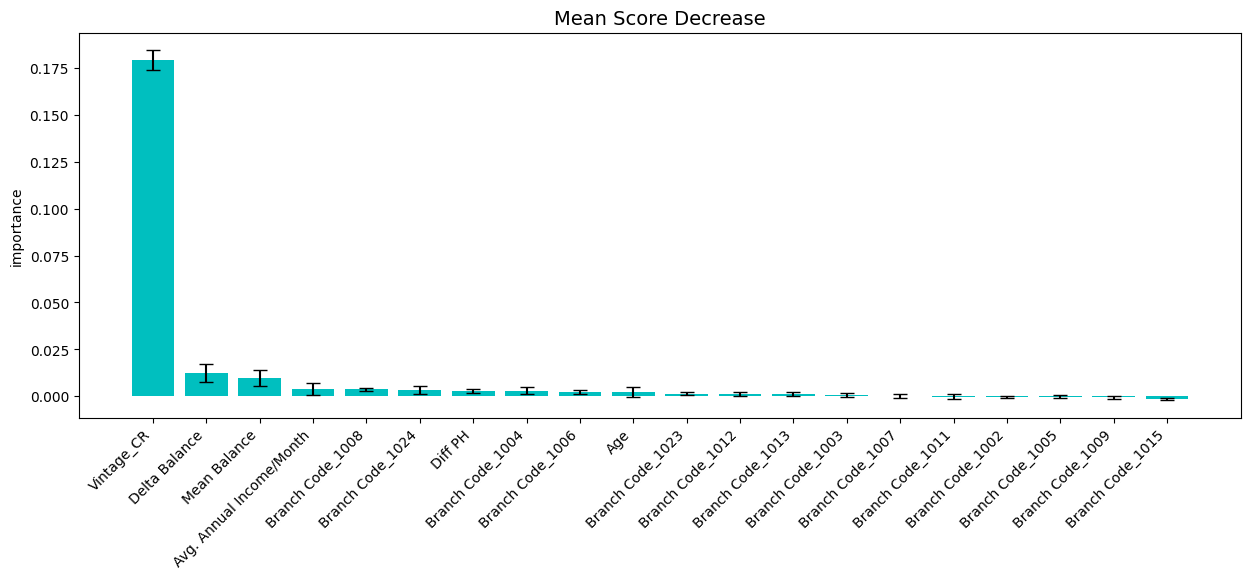

In [117]:
from jcopml.feature_importance import mean_score_decrease
df_imp1 = mean_score_decrease(x1_train, y1_train, grid, plot = True, topk =20)

In [118]:
y2_pred = grid2.predict(x2_test)

In [119]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y2_test, y2_pred))
print('Precision:', metrics.precision_score(y2_test, y2_pred))
print('Recall:', metrics.recall_score(y2_test, y2_pred))
metrics.completeness_score

Accuracy: 0.615689731159101
Precision: 0.4512396694214876
Recall: 0.33579335793357934


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

In [120]:
y2_pred_val = grid2.predict(x2_val)

In [121]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y2_val, y2_pred_val))
print('Precision:', metrics.precision_score(y2_val, y2_pred_val))
print('Recall:', metrics.recall_score(y2_val, y2_pred_val))
metrics.completeness_score

Accuracy: 0.6151302737733104
Precision: 0.45037037037037037
Recall: 0.33665559246954596


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

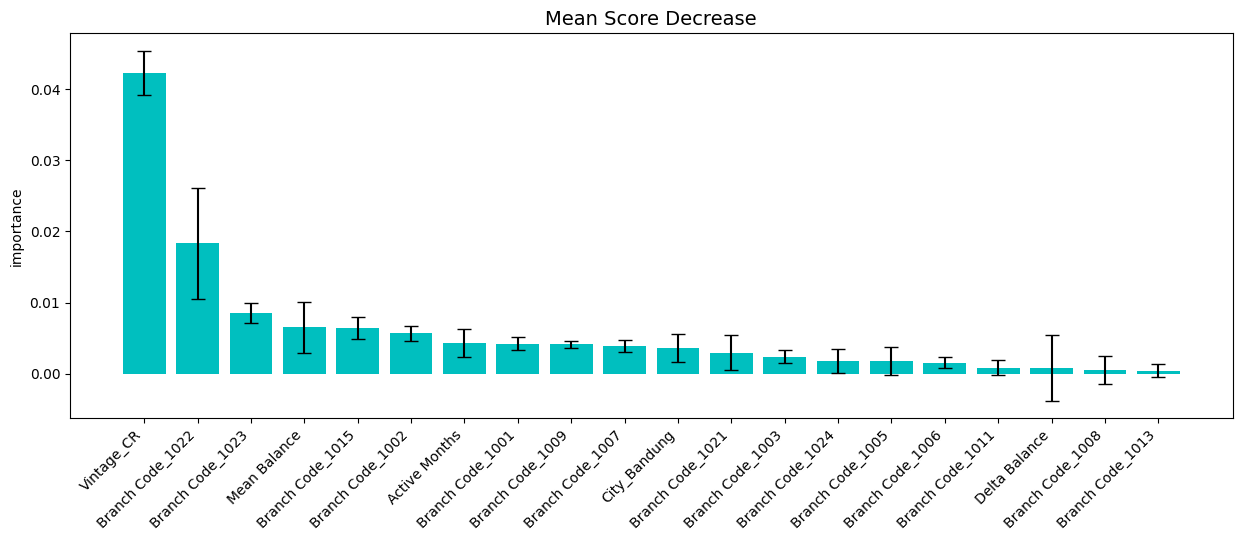

In [123]:
df_imp2 = mean_score_decrease(x2_train, y2_train, grid2, plot = True, topk =20)

#Grafient boosting

In [124]:
y11_pred = GB_Grid.predict(x1_test)

In [125]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_test, y11_pred))
print('Precision:', metrics.precision_score(y1_test, y11_pred))
print('Recall:', metrics.recall_score(y1_test, y11_pred))
metrics.completeness_score

Accuracy: 0.6826795945350375
Precision: 0.4316546762589928
Recall: 0.594059405940594


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

In [126]:
y11_pred_val = GB_Grid.predict(x1_val)

In [127]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_val, y11_pred_val))
print('Precision:', metrics.precision_score(y1_val, y11_pred_val))
print('Recall:', metrics.recall_score(y1_val, y11_pred_val))
metrics.completeness_score

Accuracy: 0.6989816161883349
Precision: 0.4539921231650555
Recall: 0.6280336800396236


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

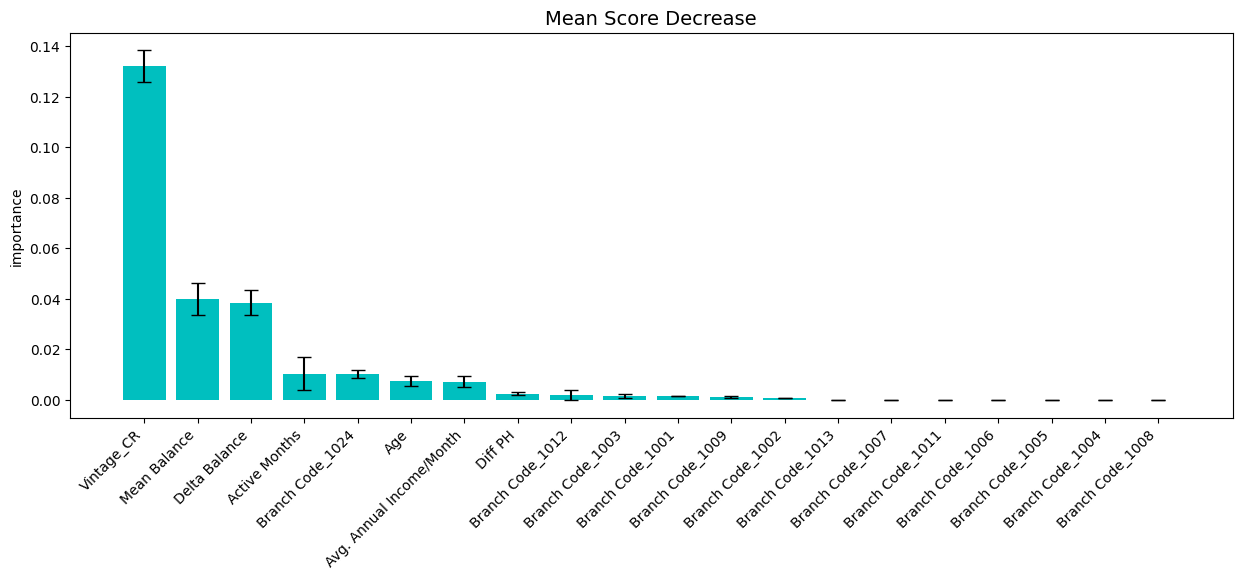

In [129]:
df_imp3 = mean_score_decrease(x1_train, y1_train, GB_Grid, plot = True, topk =20)

In [130]:
y22_pred = GB_Grid2.predict(x2_test)

In [131]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y2_test, y22_pred))
print('Precision:', metrics.precision_score(y2_test, y22_pred))
print('Recall:', metrics.recall_score(y2_test, y22_pred))
metrics.completeness_score

Accuracy: 0.3613926840017629
Precision: 0.3585409252669039
Recall: 0.991389913899139


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

In [132]:
y22_pred_val = GB_Grid2.predict(x2_val)

In [133]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y2_val, y22_pred_val))
print('Precision:', metrics.precision_score(y2_val, y22_pred_val))
print('Recall:', metrics.recall_score(y2_val, y22_pred_val))
metrics.completeness_score

Accuracy: 0.3581536833752149
Precision: 0.3580508474576271
Recall: 0.9981543004798819


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

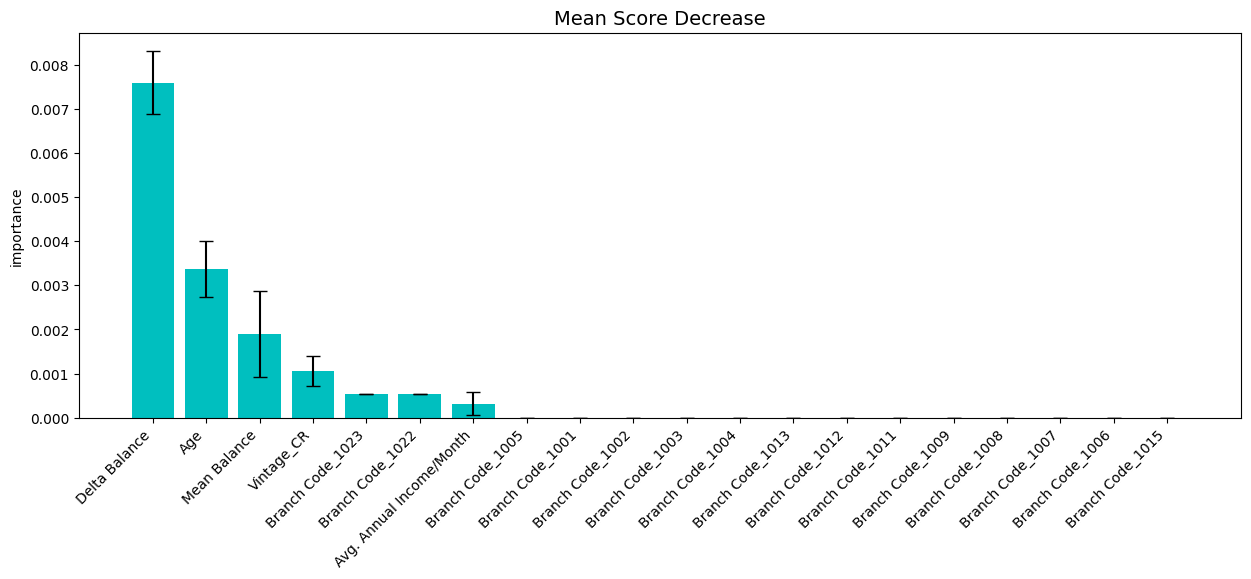

In [134]:
df_imp4 = mean_score_decrease(x2_train, y2_train, GB_Grid2, plot = True, topk =20)

#random forest

In [135]:
y12_pred = RF_Grid.predict(x1_test)

In [136]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_test, y12_pred))
print('Precision:', metrics.precision_score(y1_test, y12_pred))
print('Recall:', metrics.recall_score(y1_test, y12_pred))
metrics.completeness_score

Accuracy: 0.8074041427941825
Precision: 0.8626609442060086
Recall: 0.3316831683168317


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

In [137]:
y12_pred_val = RF_Grid.predict(x1_val)

In [138]:
from sklearn import metrics
print('Accuracy:', metrics.accuracy_score(y1_val, y12_pred_val))
print('Precision:', metrics.precision_score(y1_val, y12_pred_val))
print('Recall:', metrics.recall_score(y1_val, y12_pred_val))
metrics.completeness_score

Accuracy: 0.9133712471895252
Precision: 0.9775910364145658
Recall: 0.691431401684002


<function sklearn.metrics.cluster._supervised.completeness_score(labels_true, labels_pred)>

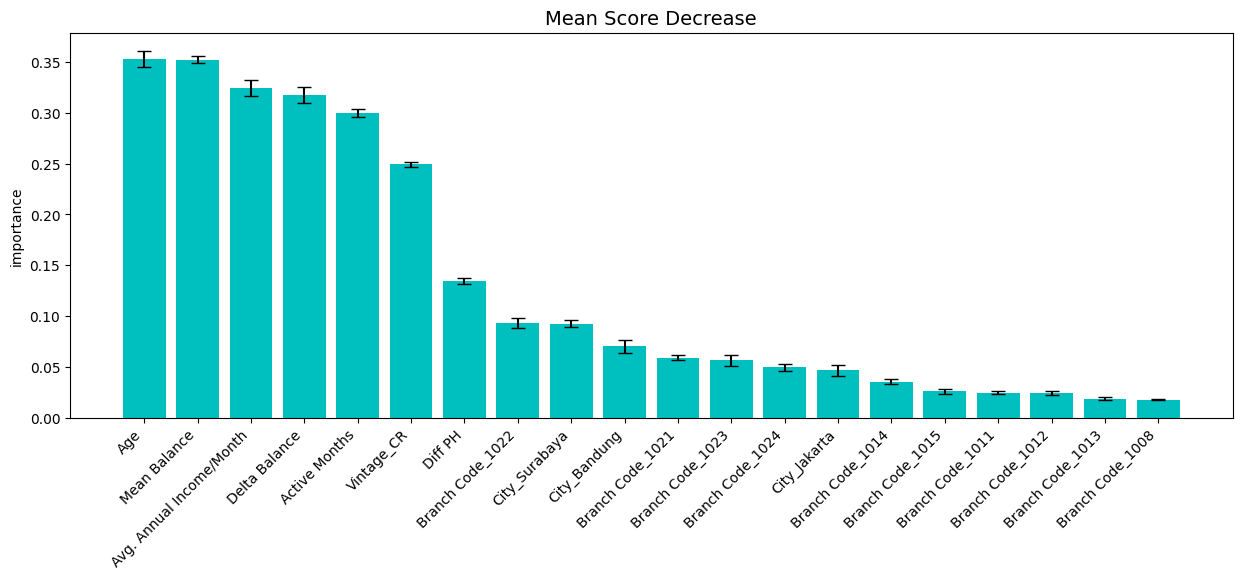

In [139]:
df_imp5 = mean_score_decrease(x1_train, y1_train, RF_Grid, plot = True, topk =20)

#KESIMPULAN
Dari semua model, rata-rata memiliki accuracy di atas 60% namun memiliki recall di bawah 40%. Artinya, masih banyak nasabah yang sebenarnya berpotensi gagal bayar namun diprediksi tidak akan gagal bayar. Sehingga bisa disampaikan bahwa dalam iterasi pembangunan model kali ini, objektif yang diinginkan masih belum dapat tercapai.

Solusi pengembangan kedepannya yang bisa dilakukan di antaranya:
1. Memperbanyak sample (jumlah nasabah dgn asumsi dataset yang tersedia saat ini bukan total populasi nasabah)
2. Melakukan oversampling terhadap kelas minoritas (gagal bayar) agar pembangunan model tidak bias
3. Memperluas horizon waktu
